# Predicciones de clasificación de imágenes

Este notebook demuestra el uso de un modelo previamente entrenado (`modelo_CNN_Aug.keras`) para realizar **predicciones de clasificación de imágenes de fondo de ojo ("normal" vs. "glaucoma"). Además, se evalúa el desempeño del modelo con una **matriz de confusión**.

Las principales actividades incluyen:

- Carga del modelo entrenado con aumento de datos.
- Visualización de imágenes de prueba de cada clase.
- Preprocesamiento de imágenes nuevas (redimensionamiento, normalización y reformateo).
- Predicción de la clase correspondiente para cada imagen usando el modelo.
- Evaluación del modelo con los datos de prueba originales.
- Visualización de la **matriz de confusión** para analizar el rendimiento del modelo por clase.

>  Esta etapa representa la validación final del modelo en condiciones reales de uso, comprobando su capacidad de generalización y precisión.


In [20]:
# Load google drive to google colab
# Herramienta de Google Colab para conectar el notebook con Google Drive
from google.colab import drive
# Monta (conecta) Google Drive en este entorno para poder leer y guardar archivos ahí
drive.mount('/content/MyDrive')

Drive already mounted at /content/MyDrive; to attempt to forcibly remount, call drive.mount("/content/MyDrive", force_remount=True).


In [21]:
import os
# Cambia la carpeta de trabajo actual a la carpeta del proyecto dentro de Drive
os.chdir('/content/MyDrive/MyDrive/Proyecto_glaucoma')


In [22]:
# Comando de terminal: lista los archivos/carpetas para revisar qué hay disponible
!ls modelo* -lth


-rw------- 1 root root 1.4M May 20 19:22 modelo_CNN_complejo_muestra_5000_epocas_100.keras
-rw------- 1 root root 1.4M May 20 18:56 modelo_CNN_complejo_muestra_5000.keras
-rw------- 1 root root 1.4M Apr 20 15:30 modelo_CNN_4.keras
-rw------- 1 root root 1.4M Apr 20 13:24 modelo_CNN_3.keras
-rw------- 1 root root 132M Apr 20 04:53 modelo_CNN_2.keras


In [23]:
from keras.models import load_model
import h5py

In [24]:
# Carga un modelo ya entrenado previamente desde un archivo .keras
model = load_model('modelo_CNN_2.keras')

In [25]:
from tensorflow.keras.utils import  array_to_img, img_to_array, load_img

In [26]:
# Comando de terminal: lista los archivos/carpetas para revisar qué hay disponible
!ls  data_2000train_200val_240test/*/*.npy

data_2000train_200val_240test/test/X_test.npy
data_2000train_200val_240test/test/y_test.npy
data_2000train_200val_240test/train/X_train.npy
data_2000train_200val_240test/train/y_train.npy
data_2000train_200val_240test/val/X_val.npy
data_2000train_200val_240test/val/y_val.npy


In [27]:
# NumPy: librería para trabajar con arreglos numéricos (matrices) de forma eficiente
import numpy as np
# Matplotlib: librería para crear gráficos y mostrar imágenes
import matplotlib.pyplot as plt
# Pandas: librería para trabajar con tablas de datos
import pandas as pd
# OpenCV: librería para leer, procesar y transformar imágenes
import cv2 as cv
from numpy import random
# 'glob' permite buscar archivos que cumplan un patrón (ej: todas las imágenes .jpg de una carpeta)
import glob
from numpy import load

import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [28]:
# Cargar los datos
X_test = load('data_2000train_200val_240test/test/X_test.npy')
y_test = load('data_2000train_200val_240test/test/y_test.npy')

print(X_test.shape)
print(y_test.shape)

(480, 220, 220, 3)
(480,)


In [29]:

##
import tensorflow as tf
X_test= tf.image.resize(X_test, (220, 220))

# Escalar los datos
X_test_scaled = X_test / 255

#  Predicciones sobre los datos de test
# Usa el modelo entrenado para generar predicciones sobre nuevas imágenes
y_pred = model.predict(X_test_scaled)

# Convertir las predicciones (one-hot) a etiquetas de clase
y_pred_classes = (y_pred > 0.5).astype(int).flatten()
y_true_classes = y_test # Assuming y_test_oct is already in class labels
y_true_classes

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [30]:
print(y_test.shape)
print(y_test[:5])

(480,)
[0 0 0 0 0]


In [31]:
# Cuenta cuántos elementos únicos hay (aquí, cuántas imágenes hay de cada clase)
print(np.unique(y_pred_classes, return_counts=True))

(array([0, 1]), array([325, 155]))


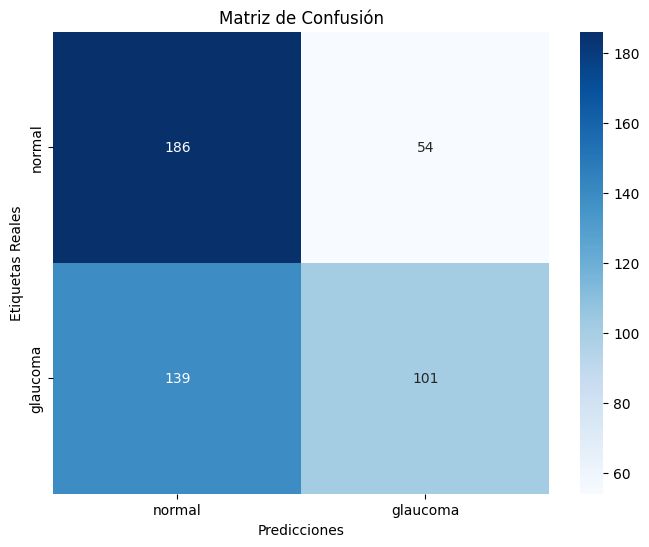

In [32]:


# Convertir los índices a las etiquetas correspondientes usando el diccionario
# Diccionario que traduce el nombre de la clase (texto) a un número (0 = normal, 1 = glaucoma) que el modelo pueda usar
labels_dict = {'normal': 0, 'glaucoma': 1}
labels = list(labels_dict.keys())

#  Calcular la matriz de confusión
# Calcula la matriz de confusión: compara las predicciones del modelo contra las etiquetas reales
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

# Display the confusion matrix using a heatmap
# Crea una nueva figura (lienzo) donde se dibujará el gráfico
plt.figure(figsize=(8, 6))
# Dibuja la matriz de confusión como un mapa de calor, más fácil de leer visualmente
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
# Agrega un título al gráfico o imagen mostrada
plt.title('Matriz de Confusión')
plt.xlabel('Predicciones')
plt.ylabel('Etiquetas Reales')
# Renderiza (dibuja) el gráfico en pantalla
plt.show()

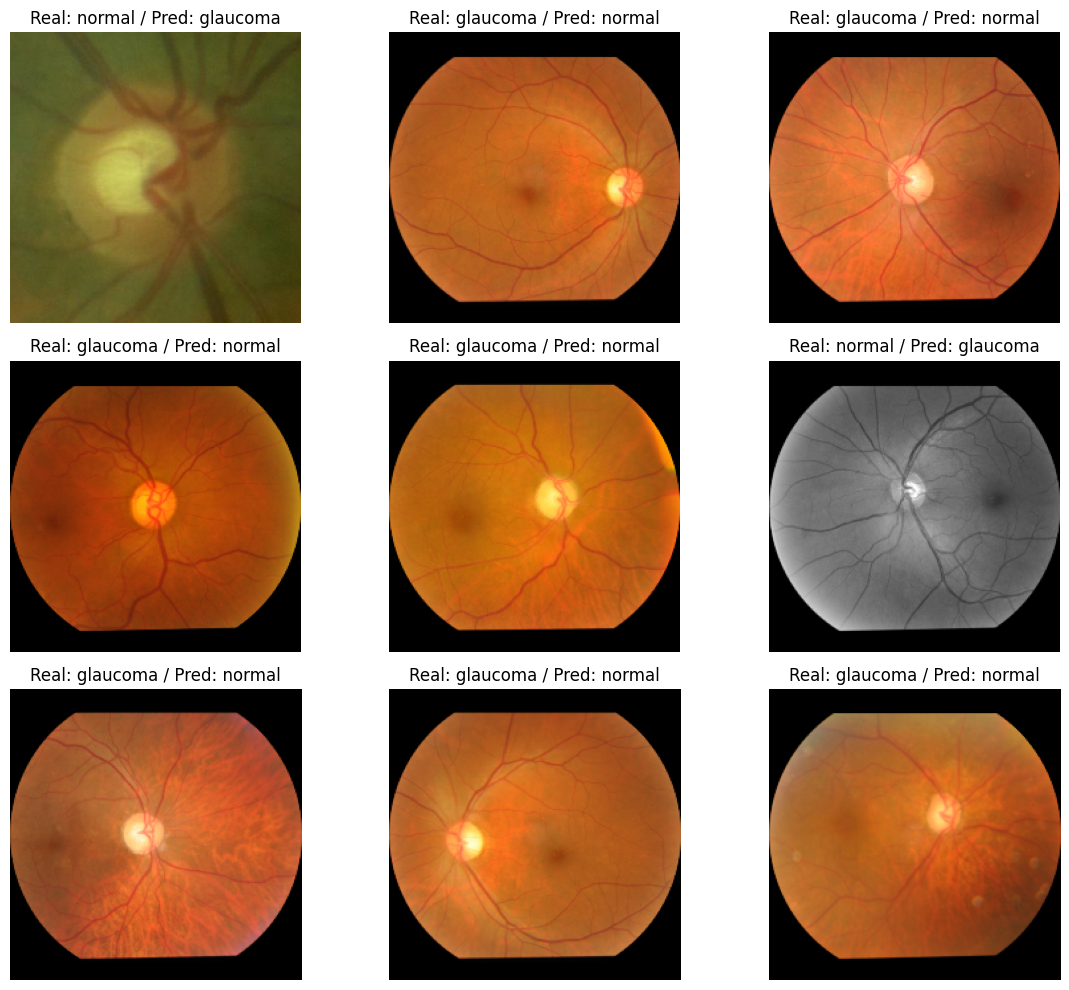

In [33]:
# Matplotlib: librería para crear gráficos y mostrar imágenes
import matplotlib.pyplot as plt
# NumPy: librería para trabajar con arreglos numéricos (matrices) de forma eficiente
import numpy as np
# OpenCV: librería para leer, procesar y transformar imágenes
import cv2

# Encontrar índices de ejemplos mal clasificados
misclassified_indices = np.where(y_pred_classes != y_true_classes)[0]

# Seleccionar aleatoriamente algunos índices mal clasificados
num_ejemplos = min(9, len(misclassified_indices))  # Mostrar hasta 9
random_misclassified_indices = np.random.choice(misclassified_indices, size=num_ejemplos, replace=False)


# Crea una nueva figura (lienzo) donde se dibujará el gráfico
plt.figure(figsize=(12, 10))

for i, idx in enumerate(random_misclassified_indices):
    img = X_test[idx].numpy().astype("uint8")  # Imagen original sin escalar
    # OpenCV lee las imágenes en formato de color BGR; esto las convierte a RGB, que es el formato correcto para mostrarlas con matplotlib
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convertir a RGB
    true_label = labels[y_true_classes[idx]]
    pred_label = labels[y_pred_classes[idx]]

    # Divide la figura en una cuadrícula y selecciona en qué posición dibujar
    plt.subplot(3, 3, i + 1)
    # Muestra una imagen en pantalla
    plt.imshow(img_rgb)
    # Agrega un título al gráfico o imagen mostrada
    plt.title(f'Real: {true_label} / Pred: {pred_label}')
    # Oculta o ajusta los ejes del gráfico (por estética)
    plt.axis('off')

plt.tight_layout()
# Renderiza (dibuja) el gráfico en pantalla
plt.show()

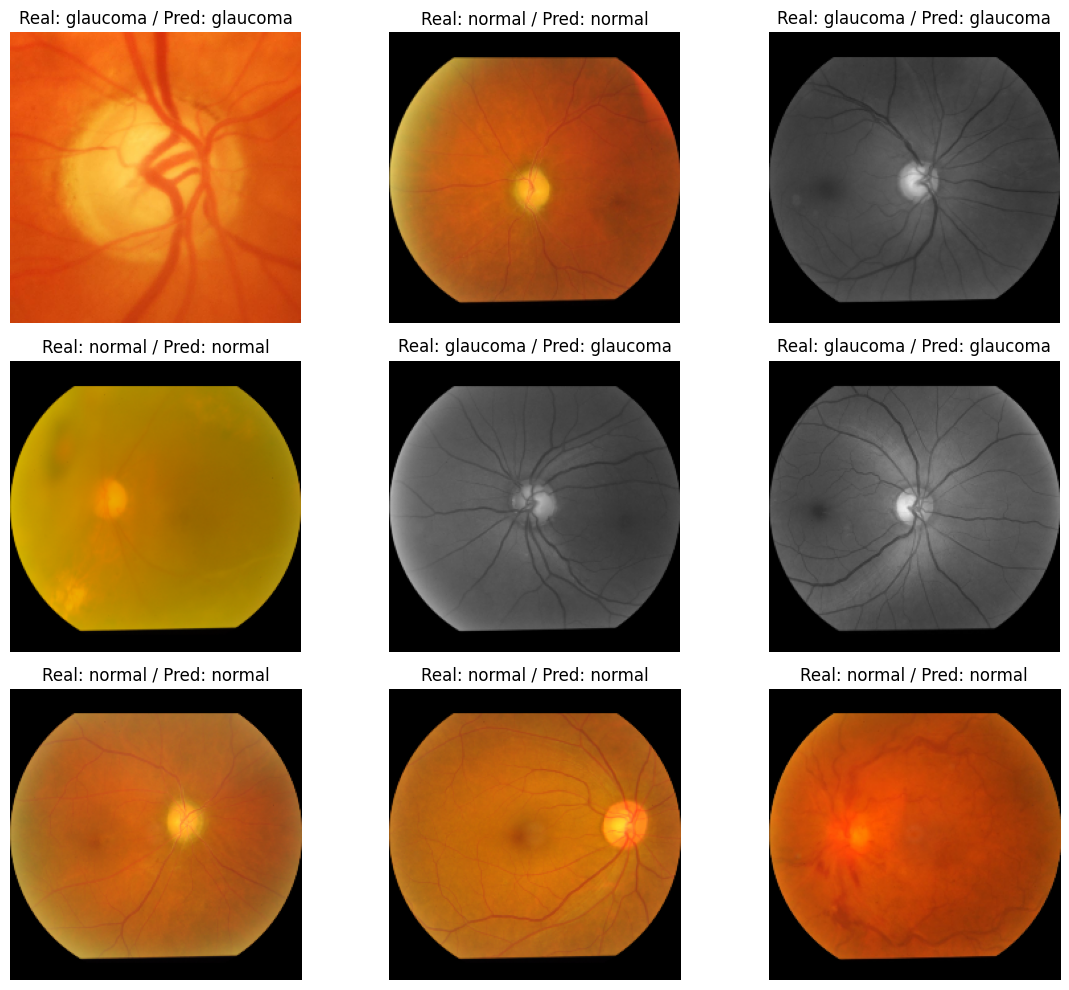

In [34]:
# Encontrar índices de ejemplos bien clasificados
correctly_classified_indices = np.where(y_pred_classes == y_true_classes)[0]

# Seleccionar aleatoriamente algunos índices bien clasificados
num_ejemplos_correctos = min(9, len(correctly_classified_indices))  # Mostrar hasta 9
random_correctly_classified_indices = np.random.choice(correctly_classified_indices, size=num_ejemplos_correctos, replace=False)

# Crea una nueva figura (lienzo) donde se dibujará el gráfico
plt.figure(figsize=(12, 10))

for i, idx in enumerate(random_correctly_classified_indices):
    img = X_test[idx].numpy().astype("uint8")  # Imagen original sin escalar
    # OpenCV lee las imágenes en formato de color BGR; esto las convierte a RGB, que es el formato correcto para mostrarlas con matplotlib
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convertir a RGB
    true_label = labels[y_true_classes[idx]]
    pred_label = labels[y_pred_classes[idx]]

    # Divide la figura en una cuadrícula y selecciona en qué posición dibujar
    plt.subplot(3, 3, i + 1)
    # Muestra una imagen en pantalla
    plt.imshow(img_rgb)
    # Agrega un título al gráfico o imagen mostrada
    plt.title(f'Real: {true_label} / Pred: {pred_label}')
    # Oculta o ajusta los ejes del gráfico (por estética)
    plt.axis('off')

plt.tight_layout()
# Renderiza (dibuja) el gráfico en pantalla
plt.show()